# 01 · Data quality
Coverage, gaps, resolution changes and DST handling for every series (produced by `src/clean.py`). Rules: UTC internally; 15-min data averaged to hourly; gaps ≤ 3 h linearly interpolated, longer gaps left missing; negative and extreme prices kept and flagged.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
R = ROOT / "reports"
plt.rcParams.update({"figure.figsize": (11, 4.2), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
ACC, BLUE, TEAL, RED, GREY = "#E08E0B", "#3F6FD8", "#1E9E92", "#D64545", "#7A8194"
pd.set_option("display.float_format", "{:,.2f}".format)
h = pd.read_parquet(ROOT / "data/processed/hourly.parquet")
h.index = h.index.tz_convert("Europe/Sofia")   # UTC internally, local only for display
p = h["price_BG"]
print(h.shape, h.index.min(), '→', h.index.max())

(33624, 75) 2023-01-01 00:00:00+02:00 → 2026-11-01 23:00:00+02:00


## Coverage and gaps per series

In [2]:
q = pd.read_csv(R / "data_quality.csv")
q[~q.series.str.startswith(("wact_", "wfc_"))].sort_values("coverage_pct").reset_index(drop=True)

,series,first,last,coverage_pct,missing_hours,interpolated,still_missing,longest_gap_h
0,gencons_energy_storage,2026-09-09 21:00:00+00:00,2026-10-31 21:00:00+00:00,3.71,32375,0,32375,32351
1,gen_energy_storage,2026-09-09 21:00:00+00:00,2026-10-31 21:00:00+00:00,3.71,32375,0,32375,32351
2,fuel_ttf_chg20,2025-06-05 22:00:00+00:00,2026-11-01 21:00:00+00:00,36.69,21288,0,21288,21288
3,fuel_ttf_vs_gasm,2025-05-08 22:00:00+00:00,2026-11-01 21:00:00+00:00,38.69,20616,0,20616,20616
4,solar_forecast,2022-12-31 22:00:00+00:00,2026-11-01 21:00:00+00:00,98.68,444,20,424,63
5,wind_forecast,2022-12-31 22:00:00+00:00,2026-11-01 21:00:00+00:00,99.58,140,1,139,39
6,load_forecast,2022-12-31 22:00:00+00:00,2026-11-01 21:00:00+00:00,99.86,48,0,48,24
7,load_actual,2022-12-31 22:00:00+00:00,2026-10-31 21:00:00+00:00,99.91,30,0,30,24
8,gen_hydro_pumped_storage,2022-12-31 22:00:00+00:00,2026-10-31 21:00:00+00:00,99.93,24,0,24,24
9,gen_hydro_run_of_river_and_pondage,2022-12-31 22:00:00+00:00,2026-10-31 21:00:00+00:00,99.93,24,0,24,24


In [3]:
w = q[q.series.str.startswith(("wact_", "wfc_"))]
print(f"Weather: {len(w)} series, coverage {w.coverage_pct.min():.2f}-{w.coverage_pct.max():.2f}%")
print(f"Share of hours where the D-1 weather forecast is a stitched proxy: {h.weather_fc_is_proxy.mean():.1%}")
print("Proxy period:", h.index[h.weather_fc_is_proxy == 1].min(), "→", h.index[h.weather_fc_is_proxy == 1].max())

Weather: 24 series, coverage 99.86-99.92%
Share of hours where the D-1 weather forecast is a stitched proxy: 29.4%
Proxy period: 2023-01-01 02:00:00+02:00 → 2024-02-16 07:00:00+02:00


## Resolution changes (15-minute MTU)
Median sampling interval per month. The day-ahead market moved to 15-minute products during the period; everything is resampled to the hourly mean so history is consistent.

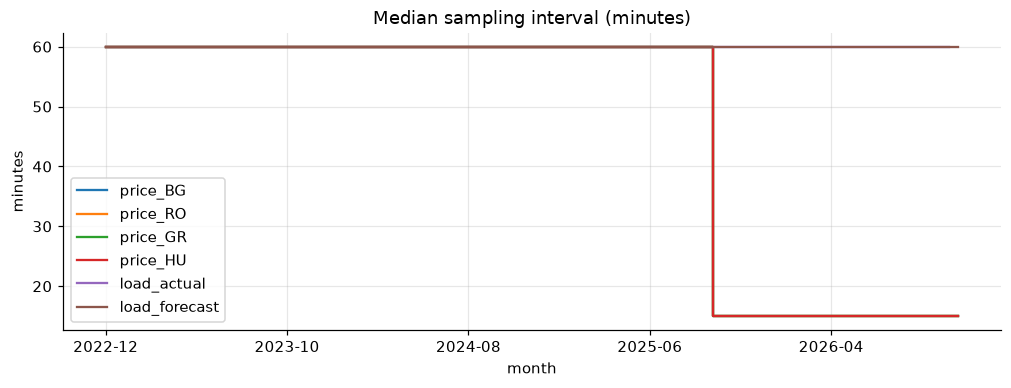

price_BG changes: {'2025-10': 15.0}
price_RO changes: {'2025-10': 15.0}
price_GR changes: {'2025-10': 15.0}
price_HU changes: {'2025-10': 15.0}


In [4]:
res = pd.read_csv(R / "resolution_by_month.csv", index_col=0)
ax = res.plot(drawstyle="steps-mid", figsize=(11, 3.5), title="Median sampling interval (minutes)")
ax.set_ylabel("minutes"); plt.show()
for c in res: 
    ch = res[c][res[c].diff().fillna(0) != 0]
    if len(ch): print(c, "changes:", ch.to_dict())

## DST: 23- and 25-hour days
Because the index is UTC, the spring and autumn clock changes appear as local days with 23 and 25 hours and need no special treatment.

In [5]:
n = p.groupby(h.index.date).size()
print(n.value_counts().sort_index())
print(n[n != 24])

price_BG
23       4
24    1393
25       4
Name: count, dtype: int64
2023-03-26    23
2023-10-29    25
2024-03-31    23
2024-10-27    25
2025-03-30    23
2025-10-26    25
2026-03-29    23
2026-10-25    25
Name: price_BG, dtype: int64


## Negative and extreme prices are real

Negative-price hours: 410 (1.22%), min -100.6 EUR/MWh
P99 = 330.0, max = 950.0 EUR/MWh


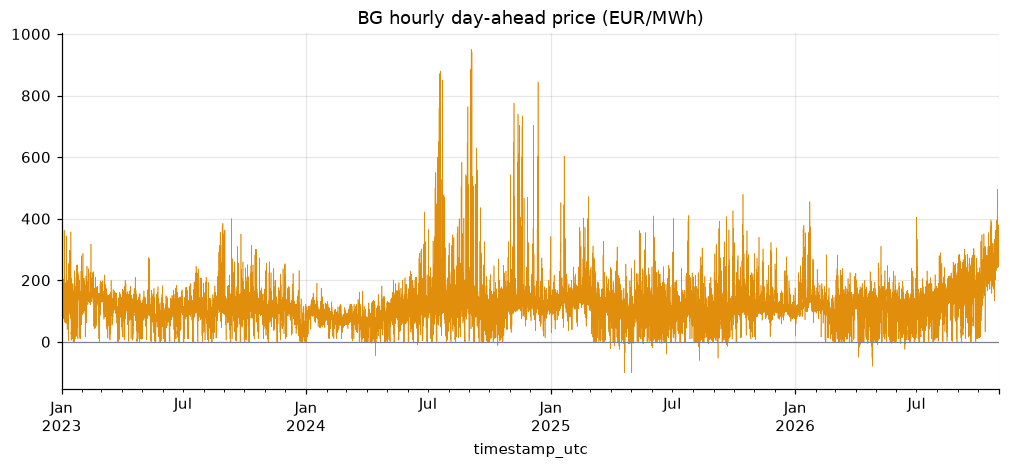

In [6]:
print(f"Negative-price hours: {int((p < 0).sum())} ({(p < 0).mean():.2%}), min {p.min():.1f} EUR/MWh")
print(f"P99 = {p.quantile(.99):.1f}, max = {p.max():.1f} EUR/MWh")
ax = p.plot(lw=.4, color=ACC, title="BG hourly day-ahead price (EUR/MWh)"); ax.axhline(0, color=GREY, lw=.8); plt.show()

**Takeaway.** The price series is complete; system forecasts have small gaps (mostly interpolated); some cross-border flow borders are not reported by ENTSO-E for parts of the period, which is why the net-import feature uses only the borders that are available. Weather forecasts before the D-1 archive starts are flagged as a proxy and excluded from the weather-uncertainty experiments.